# Fig. 6 — first-token JSD heatmaps (vector PDF)

Draws the 7-panel *first-token Jensen–Shannon distance* figure from the seven `*_jsd_matrix.csv` files in `data/jsd_matrices/`, as a vector PDF sized so LaTeX applies no scaling at `width=\textwidth`.

| quantity | value |
|---|---|
| **target width** | **164.6 mm = 6.4803 in** |
| target text height | 224 mm = 8.8189 in |

The default layout is a **3 × 3 grid** (7 panels, 2 empty slots); two alternative layouts are one config line away (see the last cell).

**Data policy:** only the seven CSV matrices are used. There are no embedded matrix values and no fallback; if a CSV is missing or invalid, execution stops before a figure is drawn.

**How to run:** in Colab, leave `DATA_DIR = ""` and upload the seven files when prompted; locally, set `DATA_DIR` to `data/jsd_matrices/`.

In [1]:
# ---- 1. Setup -------------------------------------------------------------
import json, hashlib, math, os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle

# Vector-safe PDF output: real embedded fonts (Type 42), no rasterisation.
matplotlib.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans"],
    "axes.linewidth": 0.5,
})

try:
    import seaborn as sns
    HAS_SNS = True
except Exception:
    HAS_SNS = False

print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__,
      "| seaborn", (sns.__version__ if HAS_SNS else "absent"))

numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | seaborn 0.13.2


## 2. Configuration

Everything you might want to change lives in this one cell. The geometry constants are
in **inches** and are solved so the final canvas is exactly `FIG_W_IN` wide.

In [2]:
# ---- 2. Config ------------------------------------------------------------

# Leave empty in Colab to open the upload widget. To load from a folder instead,
# set DATA_DIR to that folder (for example, a mounted Google Drive directory).
DATA_DIR = ""

# --- output ---
OUT_STEM   = "jsd_heatmaps_all"
SAVE_PNG   = True         # 600 dpi PNG alongside the PDF, for slides/preprints
PNG_DPI    = 600

# --- page geometry (from cas-sc.cls: 192mm - 2*13.7mm = 164.6mm) ---
FIG_W_IN   = 6.4803       # exact \textwidth. Do NOT change unless the class changes.
MAX_H_IN   = 8.8189       # \textheight, used only as a warning threshold

# --- layout -----------------------------------------------------------------
# "3x3"       -> one figure, 3 columns x 3 rows  (recommended: fits one page)
# "2x2_split" -> TWO figures (4 panels + 3 panels), much larger cells
# "4x2"       -> one figure matching the original PNG arrangement (small cells)
LAYOUT     = "3x3"

FIT_TO_TEXTWIDTH = True   # solve cell size from FIG_W_IN (keeps LaTeX scaling at 1.0)
CELL_IN    = 0.28         # only used when FIT_TO_TEXTWIDTH = False

# --- typography (points) ----------------------------------------------------
ANNOT_PT   = None         # None = auto-fit to the cell; or set e.g. 6.0
TICK_PT    = 6.0
TITLE_PT   = 7.5
CBAR_PT    = 6.0
ANNOT_BOLD = False
SHOW_ANNOT = True         # False -> colour-only panels, allows much smaller cells

# --- colour -----------------------------------------------------------------
CMAP_NAME  = "mako"       # seaborn mako = the palette in your PNG; falls back to viridis
VMIN       = None         # None = global min across all 7 matrices
VMAX       = None         # None = global max
SHOW_CBAR  = True
CBAR_LABEL = r"$\sqrt{\mathrm{JSD}}$ (first-token)"

SUPTITLE   = None         # None = no in-figure title (the LaTeX caption carries it)

# --- spacing (inches) -------------------------------------------------------
PAD_L, PAD_R, PAD_T, PAD_B = 0.05, 0.05, 0.05, 0.06
YLAB_IN   = 0.68          # room for "overconstrained" on the left
XLAB_IN   = 0.55          # room for 45-degree rotated bottom labels
TITLE_IN  = 0.22
COL_GAP   = 0.16
ROW_GAP   = 0.16
CBAR_GAP, CBAR_H = 0.10, 0.30
CBAR_FRAC = 0.42          # colourbar width (fraction of canvas) when placed below
CBAR_PLACEMENT = "auto"   # "auto" -> tuck it into the empty grid slots if there are any
                          # "below" -> always a strip under the whole figure

# --- the seven checkpoints, in panel order ---------------------------------
MODELS = [
    ("DistilGPT-2",           "distilgpt2"),
    ("Qwen2.5-0.5B",          "qwen2_5_0_5b"),
    ("Qwen2.5-0.5B-Instruct", "qwen2_5_0_5b_instruct"),
    ("Qwen2.5-7B",            "qwen2_5_7b"),
    ("Qwen2.5-7B-Instruct",   "qwen2_5_7b_instruct"),
    ("Llama-3.1-8B",          "llama_3_1_8b"),
    ("Llama-3.1-8B-Instruct", "llama_3_1_8b_instruct"),
]

FAMILIES = ["base", "expert", "cot", "structured", "concise",
            "overconstrained", "robust", "formatting"]

# Some exports name the first family "minimal" instead of "base".
FAMILY_ALIASES = {"minimal": "base", "baseline": "base",
                  "chain_of_thought": "cot", "chain-of-thought": "cot"}

## 3. Upload the seven CSV matrices

With `DATA_DIR = ""`, running the next cell in Colab opens one upload dialog. Select all
seven CSV files together. Filenames are checked exactly so a matrix cannot be assigned to
the wrong model silently.

In [3]:
# ---- 3. Input files -------------------------------------------------------
EXPECTED_CSV_FILES = {
    "distilgpt2": "distilgpt2_jsd_matrix.csv",
    "llama_3_1_8b_instruct": "llama_3_1_8b_instruct_jsd_matrix.csv",
    "llama_3_1_8b": "llama_3_1_8b_jsd_matrix.csv",
    "qwen2_5_0_5b_instruct": "qwen2_5_0_5b_instruct_jsd_matrix.csv",
    "qwen2_5_0_5b": "qwen2_5_0_5b_jsd_matrix.csv",
    "qwen2_5_7b_instruct": "qwen2_5_7b_instruct_jsd_matrix.csv",
    "qwen2_5_7b": "qwen2_5_7b_jsd_matrix.csv",
}

def _resolve_csv_paths():
    if DATA_DIR:
        base = Path(DATA_DIR).expanduser()
        available = {p.name: p for p in base.glob("*.csv")}
    else:
        try:
            from google.colab import files
            print("Upload all seven JSD matrix CSV files:")
            uploaded = files.upload()
            available = {Path(name).name: Path(name) for name in uploaded}
        except ImportError:
            available = {p.name: p for p in Path.cwd().glob("*.csv")}

    missing = [name for name in EXPECTED_CSV_FILES.values() if name not in available]
    if missing:
        raise FileNotFoundError(
            "Missing required CSV file(s):\n  - " + "\n  - ".join(missing) +
            "\n\nUpload all seven files together, or set DATA_DIR to their folder."
        )
    return {key: available[name] for key, name in EXPECTED_CSV_FILES.items()}

CSV_PATHS = _resolve_csv_paths()
print(f"Found all {len(CSV_PATHS)} required CSV files.")

Upload all seven JSD matrix CSV files:


Saving distilgpt2_jsd_matrix.csv to distilgpt2_jsd_matrix.csv
Saving llama_3_1_8b_instruct_jsd_matrix.csv to llama_3_1_8b_instruct_jsd_matrix.csv
Saving llama_3_1_8b_jsd_matrix.csv to llama_3_1_8b_jsd_matrix.csv
Saving qwen2_5_0_5b_instruct_jsd_matrix.csv to qwen2_5_0_5b_instruct_jsd_matrix.csv
Saving qwen2_5_0_5b_jsd_matrix.csv to qwen2_5_0_5b_jsd_matrix.csv
Saving qwen2_5_7b_instruct_jsd_matrix.csv to qwen2_5_7b_instruct_jsd_matrix.csv
Saving qwen2_5_7b_jsd_matrix.csv to qwen2_5_7b_jsd_matrix.csv
Found all 7 required CSV files.


## 4. Load the uploaded matrices

Every CSV must contain an 8 × 8 numeric matrix whose row and column labels contain the
eight prompt families. Labels are reordered to the canonical order; `minimal` is accepted
as an alias for `base`. Invalid input stops execution—there is no embedded fallback.

In [4]:
# ---- 4. Loader -------------------------------------------------------------
def _canon_family(name):
    n = str(name).strip().lower().replace(" ", "_")
    return FAMILY_ALIASES.get(n, n)

def _read_matrix_csv(path):
    df = pd.read_csv(path, index_col=0)
    df.index = [_canon_family(i) for i in df.index]
    df.columns = [_canon_family(c) for c in df.columns]

    if df.index.has_duplicates or df.columns.has_duplicates:
        raise ValueError(f"{path.name}: duplicate row or column labels")
    missing_rows = [f for f in FAMILIES if f not in df.index]
    missing_cols = [f for f in FAMILIES if f not in df.columns]
    if missing_rows or missing_cols:
        raise ValueError(
            f"{path.name}: missing rows {missing_rows or 'none'}; "
            f"missing columns {missing_cols or 'none'}"
        )

    matrix = df.loc[FAMILIES, FAMILIES].to_numpy(dtype=float)
    if matrix.shape != (8, 8):
        raise ValueError(f"{path.name}: expected an 8x8 matrix, got {matrix.shape}")
    if not np.isfinite(matrix).all():
        raise ValueError(f"{path.name}: matrix contains NaN or infinite values")
    if matrix.min() < 0 or matrix.max() > 1:
        raise ValueError(f"{path.name}: JSD values must lie in [0, 1]")
    return matrix

matrices, provenance, hashes = {}, {}, {}
for display_name, key in MODELS:
    path = CSV_PATHS[key]
    matrices[key] = _read_matrix_csv(path)
    provenance[key] = path.name
    hashes[key] = hashlib.sha256(path.read_bytes()).hexdigest()
    print(f"{display_name:24s} <- {path.name}")

print(f"\nLoaded {len(matrices)}/7 matrices from CSV.")

DistilGPT-2              <- distilgpt2_jsd_matrix.csv
Qwen2.5-0.5B             <- qwen2_5_0_5b_jsd_matrix.csv
Qwen2.5-0.5B-Instruct    <- qwen2_5_0_5b_instruct_jsd_matrix.csv
Qwen2.5-7B               <- qwen2_5_7b_jsd_matrix.csv
Qwen2.5-7B-Instruct      <- qwen2_5_7b_instruct_jsd_matrix.csv
Llama-3.1-8B             <- llama_3_1_8b_jsd_matrix.csv
Llama-3.1-8B-Instruct    <- llama_3_1_8b_instruct_jsd_matrix.csv

Loaded 7/7 matrices from CSV.


## 5. Integrity checks

Before plotting, the notebook reports symmetry, diagonal ranges, and off-diagonal summary
statistics for each uploaded matrix. The non-zero diagonal is preserved because it stores
the within-family mean pairwise distance in these files; only the MDS notebook zeroes it
before treating a matrix as pairwise distances between eight points.

In [5]:
# ---- 5. Checks -------------------------------------------------------------
rows = []
for display_name, key in MODELS:
    M = matrices[key]
    asym = float(np.abs(M - M.T).max())
    off = M[~np.eye(8, dtype=bool)]
    rows.append({
        "model": display_name,
        "file": provenance[key],
        "max_asym": round(asym, 6),
        "diag_min": round(float(np.diag(M).min()), 3),
        "diag_max": round(float(np.diag(M).max()), 3),
        "offdiag_mean": round(float(off.mean()), 4),
        "offdiag_min": round(float(off.min()), 3),
        "offdiag_max": round(float(off.max()), 3),
    })

check = pd.DataFrame(rows)
display(check)

bad_sym = check.loc[check.max_asym > 1e-9, "model"].tolist()
if bad_sym:
    print("WARNING: asymmetric matrices:", bad_sym)
else:
    print("OK: all seven uploaded matrices are symmetric.")

ALL = np.concatenate([matrices[k].ravel() for _, k in MODELS])
vmin = float(ALL.min()) if VMIN is None else VMIN
vmax = float(ALL.max()) if VMAX is None else VMAX
print(f"\nshared colour scale: vmin={vmin:.4f}  vmax={vmax:.4f}")

print("\noff-diagonal mean JSD per model:")
for row in rows:
    print(f"  {row['model']:24s} {row['offdiag_mean']:.4f}")

,model,file,max_asym,diag_min,diag_max,offdiag_mean,offdiag_min,offdiag_max
0,DistilGPT-2,distilgpt2_jsd_matrix.csv,0.0,0.507,0.544,0.0966,0.072,0.150
1,Qwen2.5-0.5B,qwen2_5_0_5b_jsd_matrix.csv,0.0,0.543,0.678,0.2702,0.148,0.359
2,Qwen2.5-0.5B-Instruct,qwen2_5_0_5b_instruct_jsd_matrix.csv,0.0,0.519,0.773,0.4156,0.156,0.601
3,Qwen2.5-7B,qwen2_5_7b_jsd_matrix.csv,0.0,0.501,0.716,0.3617,0.157,0.513
4,Qwen2.5-7B-Instruct,qwen2_5_7b_instruct_jsd_matrix.csv,0.0,0.159,0.811,0.5686,0.112,0.828
5,Llama-3.1-8B,llama_3_1_8b_jsd_matrix.csv,0.0,0.593,0.688,0.2169,0.129,0.331
6,Llama-3.1-8B-Instruct,llama_3_1_8b_instruct_jsd_matrix.csv,0.0,0.283,0.779,0.4931,0.131,0.827


OK: all seven uploaded matrices are symmetric.

shared colour scale: vmin=0.0720  vmax=0.8280

off-diagonal mean JSD per model:
  DistilGPT-2              0.0966
  Qwen2.5-0.5B             0.2702
  Qwen2.5-0.5B-Instruct    0.4156
  Qwen2.5-7B               0.3617
  Qwen2.5-7B-Instruct      0.5686
  Llama-3.1-8B             0.2169
  Llama-3.1-8B-Instruct    0.4931


## 6. The drawing code

Panels are placed with explicit inch coordinates rather than `subplots`, so the canvas
comes out at *exactly* `FIG_W_IN`. Two deliberate choices:

* every cell is a filled **rectangle**, not an `imshow` raster. `imshow` embeds an 8x8
  pixel image that some PDF viewers smooth when you zoom; rectangles stay crisp at any
  magnification, which is the whole point of the vector rebuild. The colourbar is drawn
  the same way, as 256 strips;
* `bbox_inches="tight"` is **not** used when saving - it re-crops the canvas and would
  silently undo the exact sizing;
* a panel only gets tick labels where it needs them (left edge of its row, and bottom of
  its column), which is what buys the space for legible cell numbers.

In [6]:
# ---- 6. Renderer -----------------------------------------------------------
def _cmap():
    if CMAP_NAME == "mako" and HAS_SNS:
        return sns.color_palette("mako", as_cmap=True)
    try:
        return plt.get_cmap(CMAP_NAME)
    except Exception:
        return plt.get_cmap("viridis")

def _text_colour(rgba):
    r, g, b = rgba[:3]
    lum = 0.299 * r + 0.587 * g + 0.114 * b     # perceived luminance
    return "#111111" if lum > 0.55 else "#FFFFFF"

def _auto_annot_pt(cell_in):
    # "0.52" is 4 glyphs, each ~0.55 em wide; keep it inside 85% of the cell.
    return max(4.0, min(9.0, cell_in * 72.0 * 0.85 / (4 * 0.55)))

def build_figure(panel_idx, ncols, out_stem):
    n = len(panel_idx)
    nrows = math.ceil(n / ncols)
    occ = {(i // ncols, i % ncols): panel_idx[i] for i in range(n)}

    if FIT_TO_TEXTWIDTH:
        avail = FIG_W_IN - PAD_L - YLAB_IN - (ncols - 1) * COL_GAP - PAD_R
        hm = avail / ncols
    else:
        hm = 8 * CELL_IN
    cell = hm / 8.0
    fig_w = PAD_L + YLAB_IN + ncols * hm + (ncols - 1) * COL_GAP + PAD_R

    # Can the colourbar live in the unused grid slots? If so we save its whole strip.
    empty_last = [c for c in range(ncols) if (nrows - 1, c) not in occ]
    in_slot = SHOW_CBAR and empty_last and CBAR_PLACEMENT in ("auto", "empty_slot")

    # vertical stack; orphan x-labels hang into the empty slot below them
    row_top, y = [], PAD_T + (0.22 if SUPTITLE else 0.0)
    for r in range(nrows):
        y += TITLE_IN
        row_top.append(y)
        y += hm
        if r < nrows - 1:
            y += ROW_GAP
        else:
            y += XLAB_IN
    fig_h = y + PAD_B + ((CBAR_GAP + CBAR_H) if (SHOW_CBAR and not in_slot) else 0.0)

    apt = ANNOT_PT if ANNOT_PT is not None else _auto_annot_pt(cell)
    cmap, norm = _cmap(), Normalize(vmin=vmin, vmax=vmax)
    fig = plt.figure(figsize=(fig_w, fig_h))

    def ax_at(x_in, top_in, w_in, h_in):
        return fig.add_axes([x_in / fig_w, 1 - (top_in + h_in) / fig_h,
                             w_in / fig_w, h_in / fig_h])

    for (r, c), mi in occ.items():
        disp, key = MODELS[mi]
        M = matrices[key]
        x = PAD_L + YLAB_IN + c * (hm + COL_GAP)
        ax = ax_at(x, row_top[r], hm, hm)

        # One filled rectangle per cell: pure vector, no embedded raster.
        # edgecolor == facecolor closes the hairline seams some viewers show.
        for i in range(8):
            for j in range(8):
                col = cmap(norm(M[i, j]))
                ax.add_patch(Rectangle((j, i), 1, 1, facecolor=col,
                                       edgecolor=col, linewidth=0.25))
                if SHOW_ANNOT:
                    ax.text(j + 0.5, i + 0.5, f"{M[i, j]:.2f}",
                            ha="center", va="center", fontsize=apt,
                            color=_text_colour(col),
                            fontweight=("bold" if ANNOT_BOLD else "normal"))
        ax.set_xlim(0, 8); ax.set_ylim(8, 0)

        ax.set_title(disp, fontsize=TITLE_PT, fontweight="bold", pad=2.5)
        ax.set_xticks(np.arange(8) + 0.5); ax.set_yticks(np.arange(8) + 0.5)
        ax.tick_params(length=1.5, width=0.4, pad=1.5)
        for s in ax.spines.values():
            s.set_linewidth(0.5)

        if c == 0:
            ax.set_yticklabels(FAMILIES, fontsize=TICK_PT)
        else:
            ax.set_yticklabels([])
        if (r + 1, c) not in occ:                      # nothing below -> label it
            ax.set_xticklabels(FAMILIES, fontsize=TICK_PT, rotation=45,
                               ha="right", rotation_mode="anchor")
        else:
            ax.set_xticklabels([])

    if SHOW_CBAR:
        if in_slot:
            x0 = PAD_L + YLAB_IN + empty_last[0] * (hm + COL_GAP)
            region = len(empty_last) * hm + (len(empty_last) - 1) * COL_GAP
            cw = 0.62 * region
            cax = ax_at(x0 + (region - cw) / 2, row_top[-1] + hm / 2 - 0.04, cw, 0.085)
        else:
            cw = CBAR_FRAC * fig_w
            cax = ax_at((fig_w - cw) / 2, fig_h - PAD_B - CBAR_H, cw, 0.085)
        edges = np.linspace(vmin, vmax, 257)          # 256 vector strips, not an image
        for k in range(256):
            col = cmap(norm(0.5 * (edges[k] + edges[k + 1])))
            cax.add_patch(Rectangle((edges[k], 0), edges[k + 1] - edges[k], 1,
                                    facecolor=col, edgecolor=col, linewidth=0.2))
        cax.set_xlim(vmin, vmax); cax.set_ylim(0, 1); cax.set_yticks([])
        cax.tick_params(labelsize=CBAR_PT, length=1.5, width=0.4, pad=1.5)
        cax.set_xlabel(CBAR_LABEL, fontsize=CBAR_PT, labelpad=2)
        for sp in cax.spines.values():
            sp.set_linewidth(0.5)

    if SUPTITLE:
        fig.suptitle(SUPTITLE, fontsize=TITLE_PT + 1.5, fontweight="bold",
                     y=1 - PAD_T / fig_h)

    pdf = f"{out_stem}.pdf"
    fig.savefig(pdf)                                   # no bbox_inches - keeps exact size
    if SAVE_PNG:
        fig.savefig(f"{out_stem}.png", dpi=PNG_DPI)
    plt.close(fig)
    return {"pdf": pdf, "w_in": round(fig_w, 4), "h_in": round(fig_h, 4),
            "cell_in": round(cell, 4), "annot_pt": round(apt, 2), "ncols": ncols,
            "cbar": ("empty_slot" if in_slot else "below") if SHOW_CBAR else "none",
            "panels": [MODELS[i][0] for i in panel_idx]}

jsd_heatmaps_all.pdf               6.4803 x 7.0203 in   cell 0.2242 in   numbers 6.24 pt   [OK]


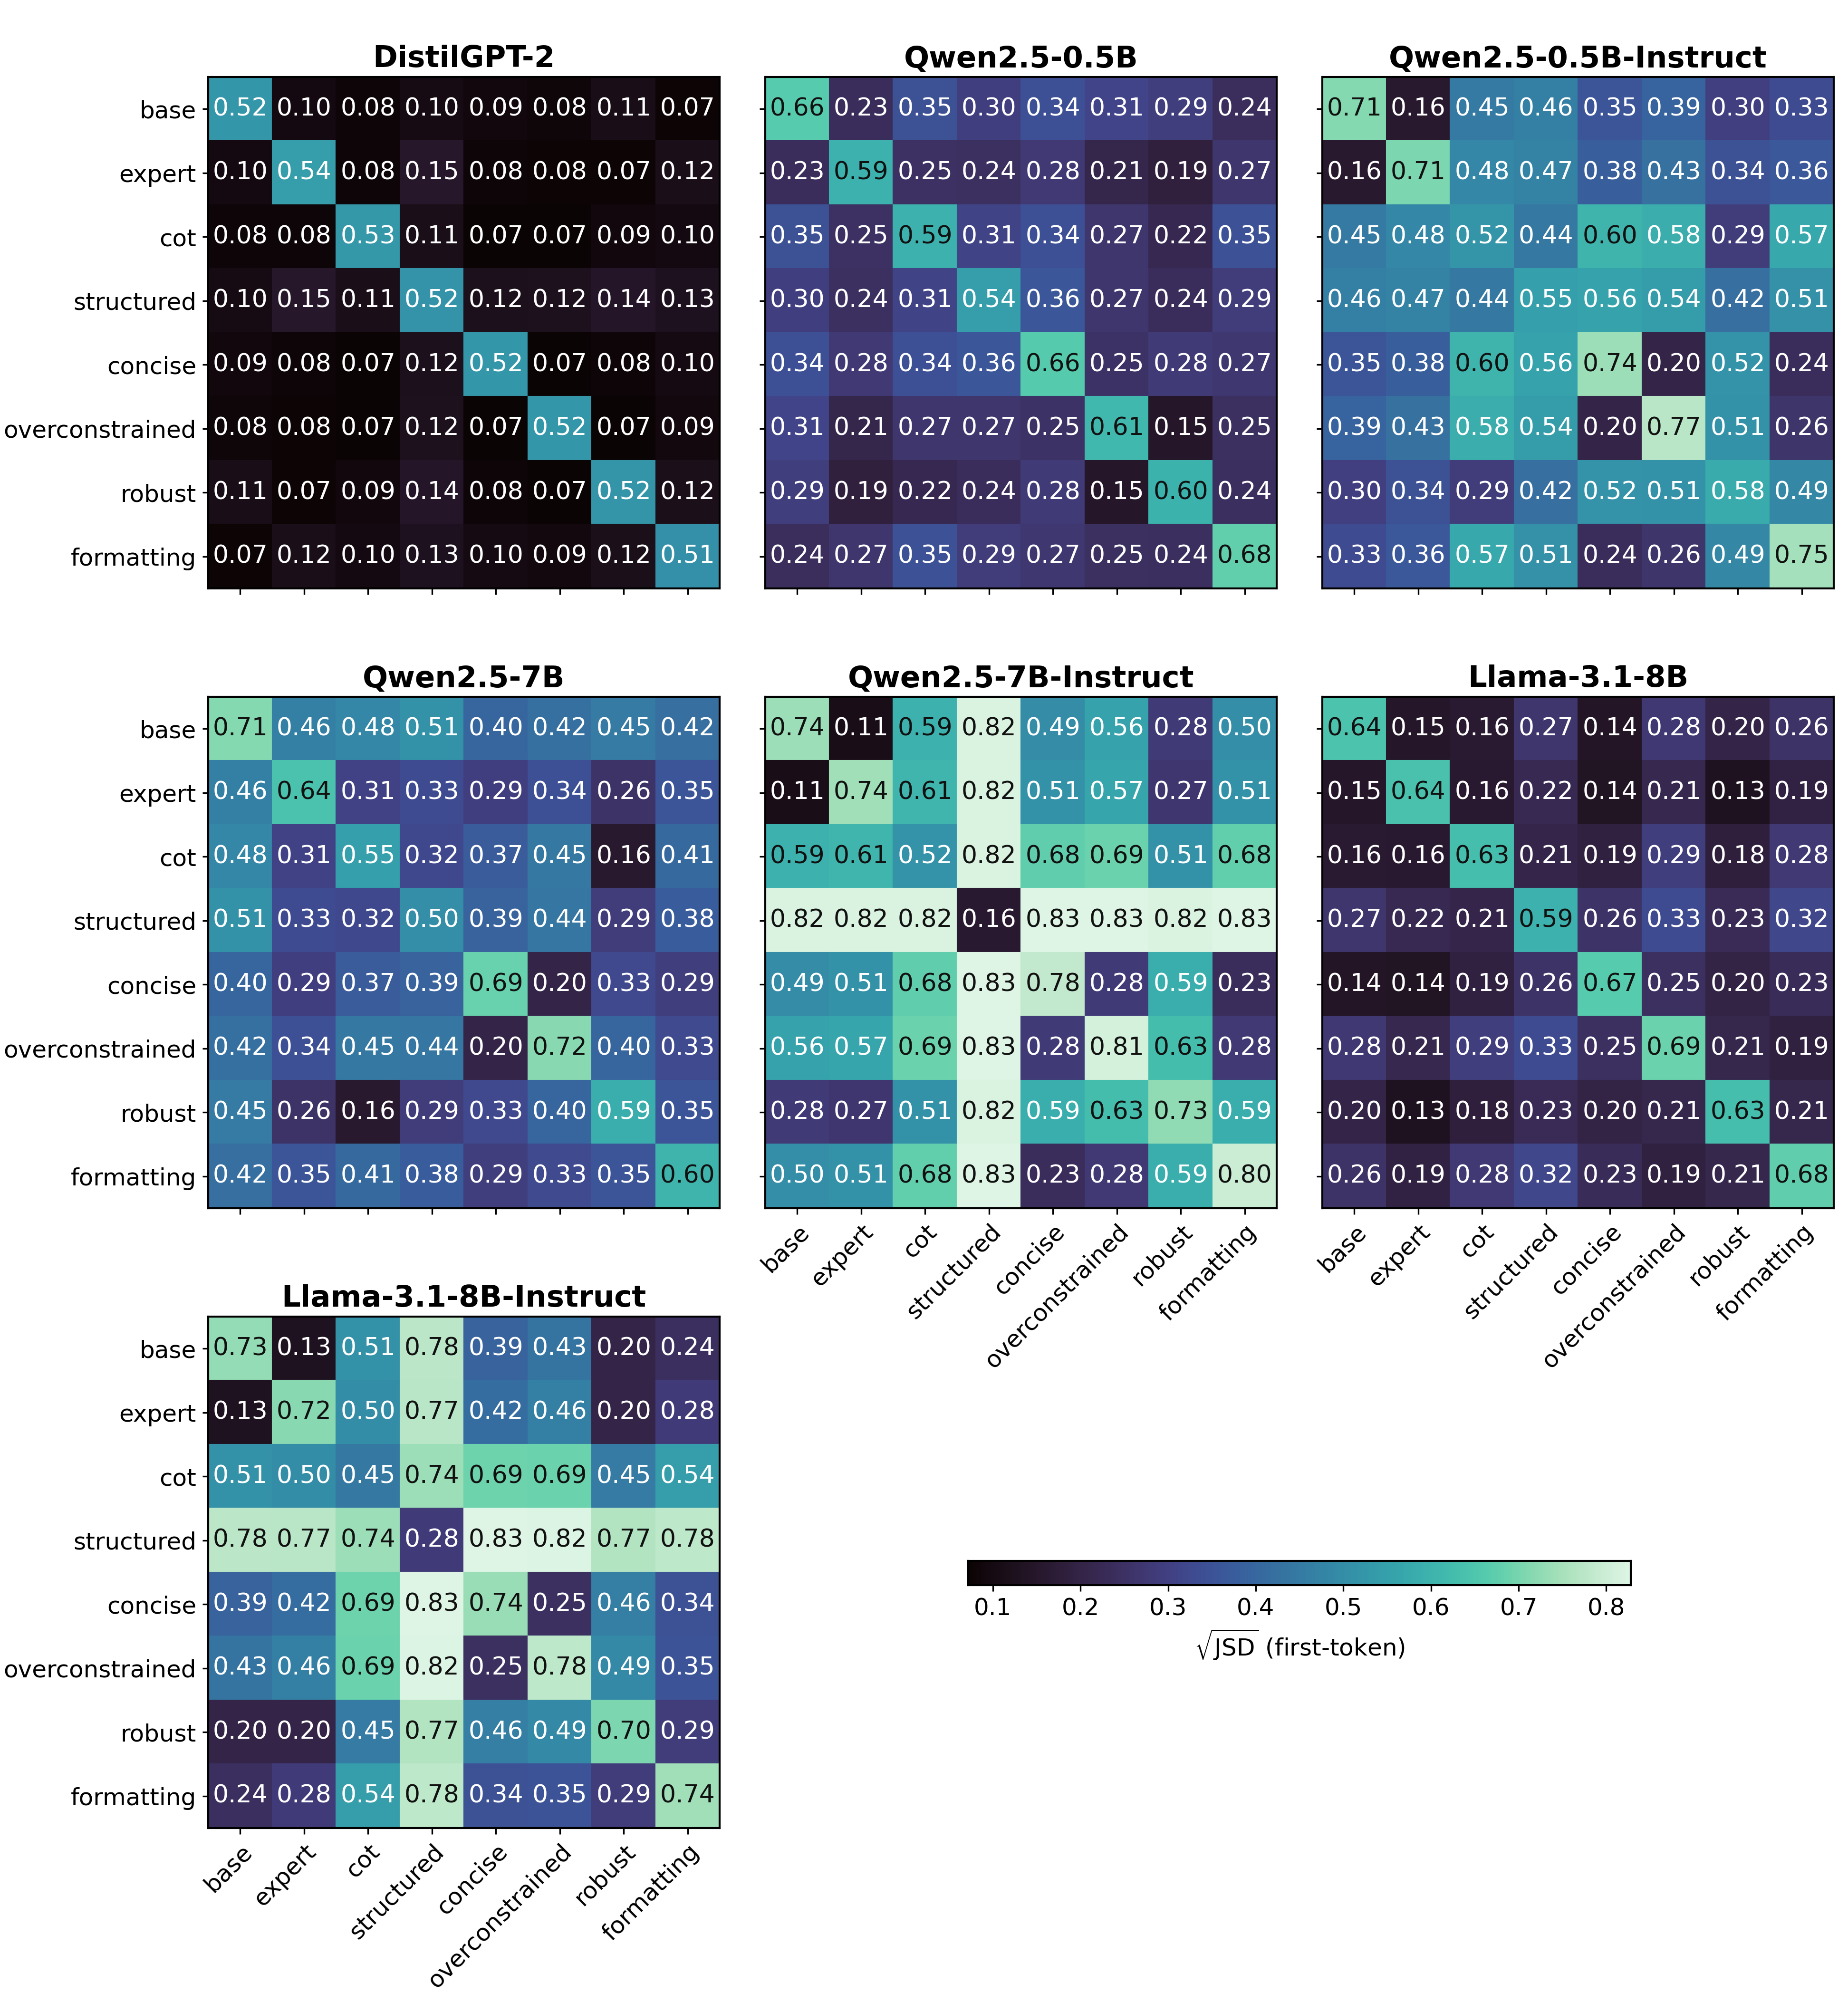

In [7]:
# ---- 7. Render -------------------------------------------------------------
LAYOUTS = {
    "3x3":       [(list(range(7)), 3, OUT_STEM)],
    "4x2":       [(list(range(7)), 4, OUT_STEM)],
    "2x2_split": [([0, 1, 2, 3], 2, f"{OUT_STEM}_part1"),
                  ([4, 5, 6],    2, f"{OUT_STEM}_part2")],
}
if LAYOUT not in LAYOUTS:
    raise ValueError(f"LAYOUT must be one of {list(LAYOUTS)}")

results = [build_figure(idx, nc, stem) for idx, nc, stem in LAYOUTS[LAYOUT]]

for r in results:
    fits = "OK" if r["h_in"] <= MAX_H_IN else "TOO TALL for one page"
    print(f"{r['pdf']:34s} {r['w_in']} x {r['h_in']} in   "
          f"cell {r['cell_in']} in   numbers {r['annot_pt']} pt   [{fits}]")
    if r["annot_pt"] < 5.5:
        print("   ! cell numbers under 5.5 pt are hard to read in print. "
              "Consider LAYOUT='2x2_split' or SHOW_ANNOT=False.")
    if r["h_in"] > MAX_H_IN:
        print("   ! exceeds \\textheight - LaTeX will shrink it and your exact sizing is lost.")

# quick on-screen preview of the first PDF
try:
    from IPython.display import display, Image
    if SAVE_PNG:
        display(Image(filename=results[0]["pdf"].replace(".pdf", ".png"), width=900))
except Exception:
    pass

## 8. Manifest and download

Writes a JSON provenance record (input hashes, library versions, layout, colour scale) next to the figures.

In [8]:
# ---- 8. Manifest -----------------------------------------------------------
import sys, platform
manifest = {
    "figure": "jsd_heatmaps_all (first-token JSD between prompt families)",
    "generated_for": "cas-sc single column, textwidth 164.6mm = 6.4803in",
    "layout": LAYOUT,
    "outputs": results,
    "colour": {"cmap": CMAP_NAME, "vmin": vmin, "vmax": vmax,
               "shared_scale": True, "annotations": SHOW_ANNOT},
    "families": FAMILIES,
    "provenance": provenance,
    "input_sha256": hashes,
    "checks": check.to_dict(orient="records"),
    "versions": {"python": sys.version.split()[0], "numpy": np.__version__,
                 "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
                 "seaborn": (sns.__version__ if HAS_SNS else None),
                 "platform": platform.platform()},
}
with open(f"{OUT_STEM}_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)
print(json.dumps({k: manifest[k] for k in ["layout", "outputs", "colour", "provenance"]}, indent=2))

try:
    from google.colab import files
    for r in results:
        files.download(r["pdf"])
        if SAVE_PNG:
            files.download(r["pdf"].replace(".pdf", ".png"))
    files.download(f"{OUT_STEM}_manifest.json")
except Exception:
    print("\nNot in Colab - files are in the working directory.")

{
  "layout": "3x3",
  "outputs": [
    {
      "pdf": "jsd_heatmaps_all.pdf",
      "w_in": 6.4803,
      "h_in": 7.0203,
      "cell_in": 0.2242,
      "annot_pt": 6.24,
      "ncols": 3,
      "cbar": "empty_slot",
      "panels": [
        "DistilGPT-2",
        "Qwen2.5-0.5B",
        "Qwen2.5-0.5B-Instruct",
        "Qwen2.5-7B",
        "Qwen2.5-7B-Instruct",
        "Llama-3.1-8B",
        "Llama-3.1-8B-Instruct"
      ]
    }
  ],
  "colour": {
    "cmap": "mako",
    "vmin": 0.072,
    "vmax": 0.828,
    "shared_scale": true,
    "annotations": true
  },
  "provenance": {
    "distilgpt2": "distilgpt2_jsd_matrix.csv",
    "qwen2_5_0_5b": "qwen2_5_0_5b_jsd_matrix.csv",
    "qwen2_5_0_5b_instruct": "qwen2_5_0_5b_instruct_jsd_matrix.csv",
    "qwen2_5_7b": "qwen2_5_7b_jsd_matrix.csv",
    "qwen2_5_7b_instruct": "qwen2_5_7b_instruct_jsd_matrix.csv",
    "llama_3_1_8b": "llama_3_1_8b_jsd_matrix.csv",
    "llama_3_1_8b_instruct": "llama_3_1_8b_instruct_jsd_matrix.csv"
  }
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Putting it in the paper

Default (`LAYOUT = "3x3"`), one full-width float:

```latex
\begin{figure}[!t]
  \centering
  \includegraphics[width=\textwidth]{jsd_heatmaps_all.pdf}
  \caption{First-token Jensen--Shannon distance between prompt families for each of the
  seven checkpoints, on a shared colour scale. Diagonal entries are the mean within-family
  pairwise distance across the 127 canonical prompts and are therefore not zero.}
  \label{fig:jsd}
\end{figure}
```

Do **not** add `scale=`, `height=`, or a second size key. The canvas is already exactly
`\textwidth`; adding a height key scales the figure non-uniformly.

If you switch to `LAYOUT = "2x2_split"` you get `..._part1.pdf` and `..._part2.pdf`,
which go in two floats (or one float with two `\includegraphics` lines).

### Knobs, in the order you are most likely to need them

| symptom | change |
|---|---|
| numbers too small in print | `LAYOUT = "2x2_split"` (cells roughly 55% larger) |
| figure too tall for the page | `SHOW_ANNOT = False`, or `LAYOUT = "4x2"` |
| want the original PNG arrangement | `LAYOUT = "4x2"` |
| low contrast at the dark end | set `VMIN = 0.0`, or `VMIN`/`VMAX` to a tighter range |
| palette should change | `CMAP_NAME` (`"mako"`, `"viridis"`, `"crest"`) |
| labels clipped on the left | raise `YLAB_IN` |
| in-figure title wanted | set `SUPTITLE` to the title string |
| colourbar should sit under everything | `CBAR_PLACEMENT = "below"` |